In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

REPO_ROOT = Path.cwd().parent
# make the shared code in src/ importable even when the package is not pip-installed
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from egypt_survey_ml.config import DatasetConfig
from egypt_survey_ml.dataset import prepare_dataset
from egypt_survey_ml.training import ModelTrainer
from egypt_survey_ml.paths import DataPaths

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## Dataset creation

First we create the dataset config, here we define the scenario settings. MASK_PATH is used as a basis to select the features we use for training. 

Extra variables can be specified in a list for male/female using the *male_extra_columns* / *female_extra_columns* variables.
Likewise, variables to be excluded can also be specified in a list, using the *male_exclude_columns* / *female_exclude_columns* variables.


These selections will overwrite the selections from MASK_PATH, with exclusions having the highes prioriry.
<br>
<br>
<br>
The outlier cap for male and female wages can also be specified with *male_outlier_cap* and *female_outlier_cap*.

In [2]:
# --- scenario settings -------------------------------------------------
# Every value below can be changed to test a different scenario. Defaults live in
# src/egypt_survey_ml/config.py (DatasetConfig); anything left out keeps its default
# (rng_seed=42, min_working_age=15, weeks_per_month=365.25/7/12).
# Column-selection workbook, separate from the command-area data_filename below.
# Sheet1: variable = column name, correl = 1 to include (0 to exclude), type = binary/
# categorical/numerical; remarks is ignored. Selected columns that are not in the data are
# skipped (same as the training notebooks). The saved models always get the columns they
# were trained on, so the mask only sets the default feature set of the dataset.
MASK_PATH = (
    Path.home()
    / "OneDrive - Stichting Deltares"
    / "PhD/Egypt_ERF_data/Data/variable_selection.xlsx"
)

cfg = DatasetConfig(
    include_empstab=True,  # see design-decisions table above: circular under the zero-inclusive regime
    include_hrswk=True,  # team decision (Vanni's email) excludes hours for the female model;
    # the audit branch's train-catboost_raw*.ipynb notebooks all keep it
    # for female too. Toggle this to test how much of their higher
    # reported R2 comes from that one feature, holding everything else
    # (repeated eval, intensive-margin decomposition, wage formula, cap)
    # fixed at our more rigorous setup.
    zero_handling="drop_random",  # one of: "none", "drop_random", "lognormal_synthetic"
    predict_log_wage=False,
    include_ribasim=True,
    wage_perturbation=False,
    wage_perturbation_sigma=0.03,
    drop_random_frac=1.0,  # only used when zero_handling == "drop_random"
    male_outlier_cap=10000,
    female_outlier_cap=np.inf,
    data_filename="Data/data_correlation.xlsx",
    #male_extra_columns=["water_supply", "water_productivity"],
    male_exclude_columns = [
    "female_violence_sexual",
    "female_violence_emotional",
    "female_violence_physical",
    "female_child_married",
    "female_circumcised",
    "female_healthcare_decision",
    "female_contraceptives_decision",
    "female_labour_participation_rate",
    "female_unemployment_rate",
]

)

In [3]:
# Loads the survey, builds household wage context, makes the sex-stratified train/test split and the
# wage target, attaches governorates, and loads the command-area data and feature mask
# (see src/egypt_survey_ml/dataset.py).
_ONEDRIVE = "OneDrive - Stichting Deltares"
_EGYPT_DIR = "PhD/Egypt_ERF_data"
_LFS_DIR = "Data/hh_data"

paths = DataPaths.from_onedrive(
    onedrive_dir=_ONEDRIVE,
    egypt_dir=_EGYPT_DIR,
    lfs_dir=_LFS_DIR,
    data_filename=cfg.data_filename,
)
ds = prepare_dataset(cfg, paths=paths, mask_path=MASK_PATH)

train_pool = ds.train_pool
test_pool = ds.test_pool
survey_columns = ds.survey_columns
excel_df = ds.excel_df
EXCEL_PATH = ds.paths.excel_path

data source: OneDrive (C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data)
OK   C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\hh_data\Egypt 2022-LFS IND-V1.dta
OK   C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\hh_data\Egypt 2022-LFS HH-V1.dta
OK   C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\crosswalk\reg_governorate_crosswalk.csv
OK   C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\crosswalk\command_area_governorate_crosswalk.csv
OK   C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\variable_selection.xlsx
OK   C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\other_data\population_density_matrix.csv
OK   C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\data_correlation.xlsx
individual shape: (299423, 106)  household shape: (76976, 116)
household_wage_total / wage_ratio computed for 45426 rural house

In [4]:
from pathlib import Path

onedrive = Path.home() / _ONEDRIVE
print("Currently looking in:", onedrive / _EGYPT_DIR)

egypt_root = onedrive / "PhD" / "Egypt_ERF_data"
print("Expected folder:", egypt_root)
print("Folder exists:", egypt_root.is_dir())

Currently looking in: C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data
Expected folder: C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data
Folder exists: True


## Define ModelTrainer to train the models

We use the created dataset for the model training. We also specify paths to the hyperparameter tuning results. These are used to get the hyperparameters for the specified seeds for command unit assignment when training the models. If a seed is not found in the hyperparameter tuning results, default values will be used instead.

In [5]:
trainer = ModelTrainer(
    ds=ds,
    male_hp_path=REPO_ROOT
    / "models/hp_tuning/hp_outcome_with_hrs_regression_male_22.csv",
    female_hp_path=REPO_ROOT
    / "models/hp_tuning/hp_outcome_with_hrs_regression_female_22.csv",
    cls_hp_path=REPO_ROOT / "models/hp_tuning/hp_outcome_classification.csv",
)

## Train one iteration
You can train one realization of the command unit assignment using the "run_once" function. This will train the regression model using a specified dataset or the dataset passed to ModelTrainer if no dataset is provided here. To train one realization of the classifier, use "run_once_classifier" instead.

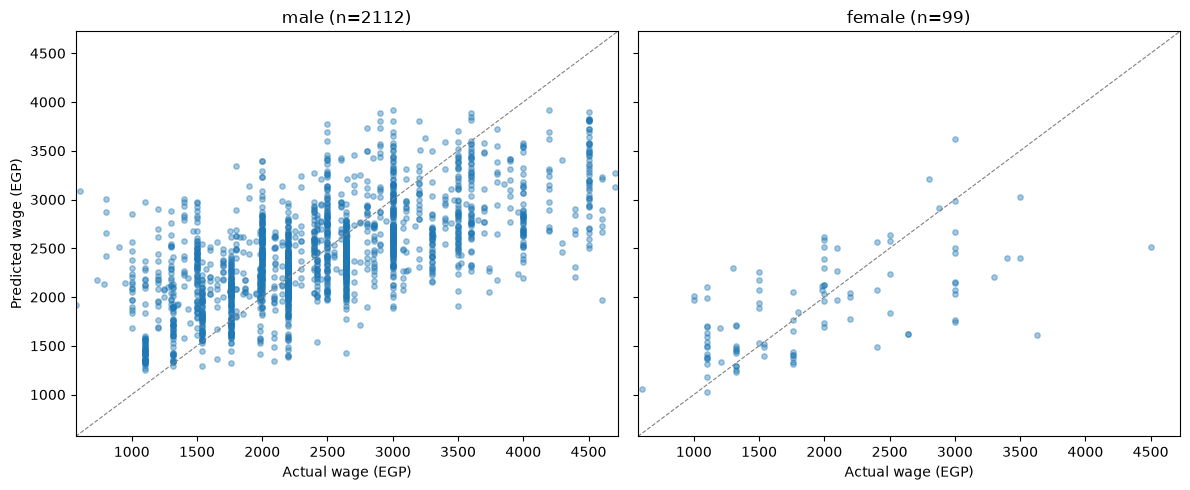

In [6]:
results, gap, store = trainer.run_once(
    ds=None, seed=42, iterations=500, early_stopping_rounds=200
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, sex_label in zip(axes, ["male", "female"]):
    info = store[sex_label]
    y_true, y_pred = info["y_test"], info["y_pred"]
    ax.scatter(y_true, y_pred, alpha=0.4, s=15)
    lims = [
        0.95 * min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max()) * 1.05,
    ]
    ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Actual wage (EGP)")
    ax.set_title(f"{sex_label} (n={len(y_true)})")
axes[0].set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()

=== male SHAP summary ===


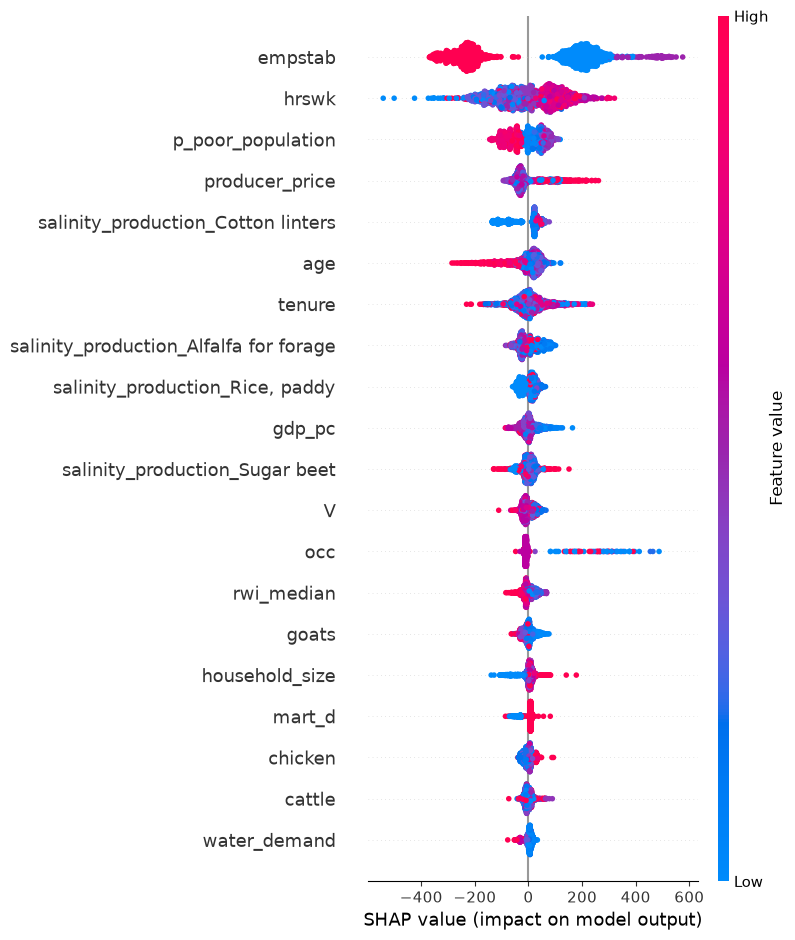

=== female SHAP summary ===


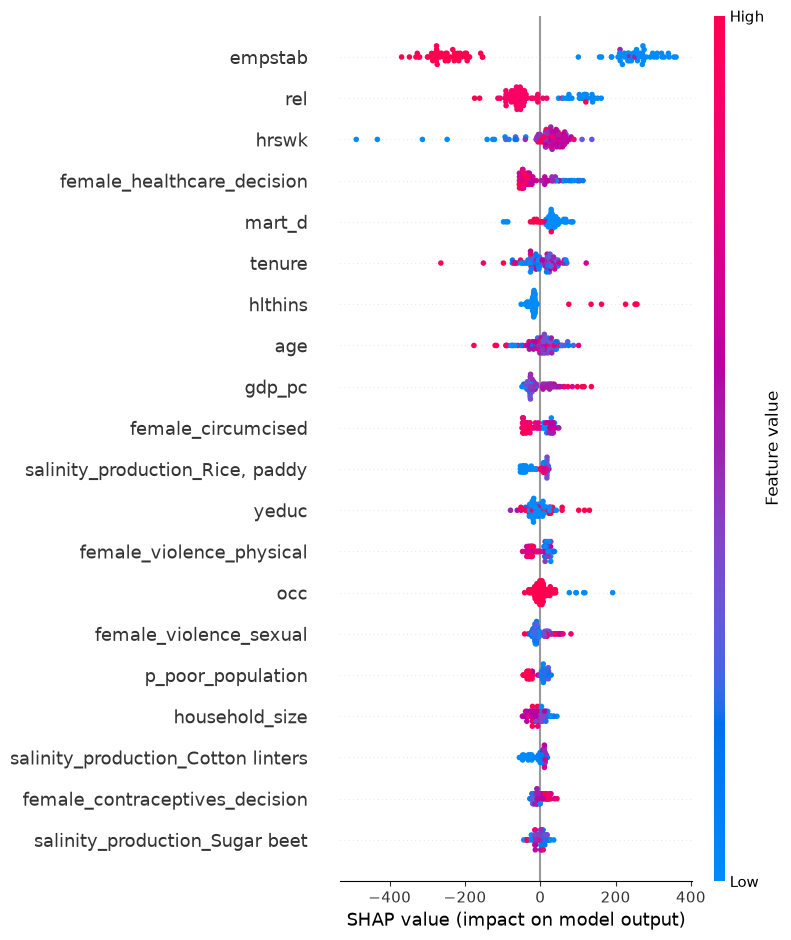

In [7]:
for _sex_label in ["male", "female"]:
    _info = store[_sex_label]
    _explainer = shap.TreeExplainer(_info["model"])
    _shap_values = _explainer.shap_values(_info["X_test"])
    print(f"=== {_sex_label} SHAP summary ===")
    shap.summary_plot(_shap_values, _info["X_test"], show=True)
    # shap.dependence_plot("hrswk", _shap_values, _info["X_test"])

Model type: CatBoostRegressor
Workers below 10 million: 0


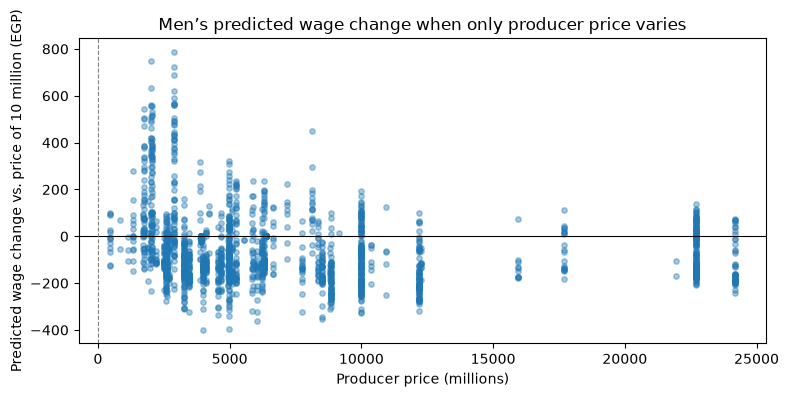

In [8]:
import matplotlib.pyplot as plt

info = store["male"]
model = info["model"]
X = info["X_test"]
price = X["salinity_production_Wheat"]
reference = 1

wage_observed = model.predict(X)
wage_reference = model.predict(X.assign(producer_price=reference))
change = wage_observed - wage_reference

below = price < reference
print("Model type:", type(model).__name__)
print("Workers below 10 million:", below.sum())
if below.any():
    print("Largest difference below 10 million (EGP):", change[below].max())
    print("Workers above zero by more than 0.01 EGP:", (change[below] > 0.01).sum())

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(price / 1, change, alpha=0.4, s=15)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(10, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("Producer price (millions)")
ax.set_ylabel("Predicted wage change vs. price of 10 million (EGP)")
ax.set_title("Men’s predicted wage change when only producer price varies")
plt.tight_layout()
plt.show()

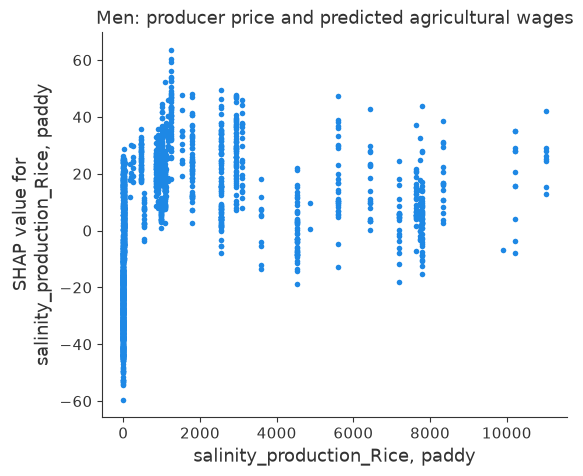

In [9]:
_info = store["male"]
X_male = _info["X_test"]

explainer_male = shap.TreeExplainer(_info["model"])
shap_male = explainer_male.shap_values(X_male)

shap.dependence_plot(
    "salinity_production_Rice, paddy",
    shap_male,
    X_male,
    interaction_index=None,
    title="Men: producer price and predicted agricultural wages",
)

In [ ]:
results_c, gap_c, store_c = trainer.run_once_classifier(
    ds=None, seed=42, iterations=500
)

for _sex_label in ["male", "female"]:
    _info = store_c[_sex_label]
    _explainer = shap.TreeExplainer(_info["model"])
    _shap_values = _explainer.shap_values(_info["X_test"])
    print(f"=== {_sex_label} SHAP summary ===")
    shap.summary_plot(_shap_values, _info["X_test"], show=True)
    # shap.dependence_plot("hrswk", _shap_values, _info["X_test"])

## Training and saving multiple realizations
Training multiple realizations can be done with the "run_models" function. This will run both the regression and classification models for both male and female. The models are saved along with a metrics file, containing the used seeds and the model scores. If you only want to train regression or classification, use 'kind="regressor"' or 'kind="classifier' as an argument. 

The directory to which the models are saved can be specified using the 'model_dir' argument. This directory can either be an absolute path or a relative path to the models directory within this repository. 

A list of seeds can be specified for the realizations. If no seeds are specified, all common seeds within the hyper parameter tuning files are used instead.

In [ ]:
trainer.run_models(ds=None, iterations=500, seeds=range(42, 43)) #142